# 01 · Sensor data exploration (real data)

**NASA IMS bearings** (Univ. of Cincinnati IMS / NASA PCoE): four bearings on one shaft at 2,000 rpm, a 20,480-sample
snapshot at 20 kHz every 10 minutes, run until failure. Each raw file is a tab-separated text file named by timestamp
with no extension. `src/preprocessing.py` converts each snapshot into time- and frequency-domain features.

| Test | Folder | Channels | Failure |
|---|---|---|---|
| test1 | `1st_test` | 8 (x,y per bearing; x used) | bearing 3 inner race, bearing 4 roller element |
| test2 | `2nd_test` | 4 | bearing 1 outer race |
| test3 | `4th_test/txt` | 4 | bearing 3 outer race |

**NAB** (Numenta Anomaly Benchmark): real-world labelled time series. We use five `realKnownCause` / `realAWSCloudwatch`
series, chosen because they are machine or service telemetry with documented incidents.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

one raw snapshot: (20480, 4)


[Text(0.5, 0, 'ms'),
 Text(0, 0.5, 'acceleration (g)'),
 Text(0.5, 1.0, 'test2 bearing 1, first snapshot (100 ms)')]

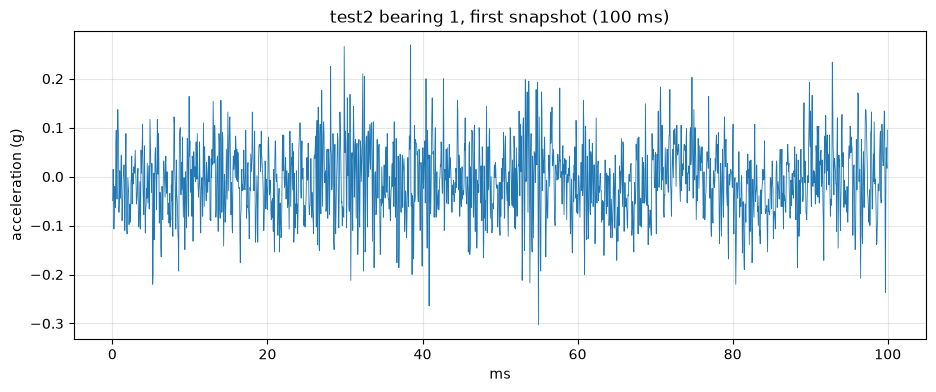

In [2]:
from src.preprocessing import IMS_TESTS, list_snapshots, read_snapshot, load_ims_features, load_all_nab
raw = read_snapshot(list_snapshots(IMS_TESTS[1])[0])
print("one raw snapshot:", raw.shape)
t = np.arange(2000) / 20000
fig, ax = plt.subplots()
ax.plot(t * 1000, raw[:2000, 0], lw=0.6); ax.set(xlabel="ms", ylabel="acceleration (g)", title="test2 bearing 1, first snapshot (100 ms)")

In [3]:
f = load_ims_features()
f.groupby("test_id").agg(rows=("rms", "size"), bearings=("bearing", "nunique"), start=("timestamp", "min"), end=("timestamp", "max"))

,rows,bearings,start,end
test_id,,,,
test1,8624,4,2003-10-22 12:06:24,2003-11-25 23:39:56
test2,3936,4,2004-02-12 10:32:39,2004-02-19 06:22:39
test3,25296,4,2004-03-04 09:27:46,2004-04-18 02:42:55


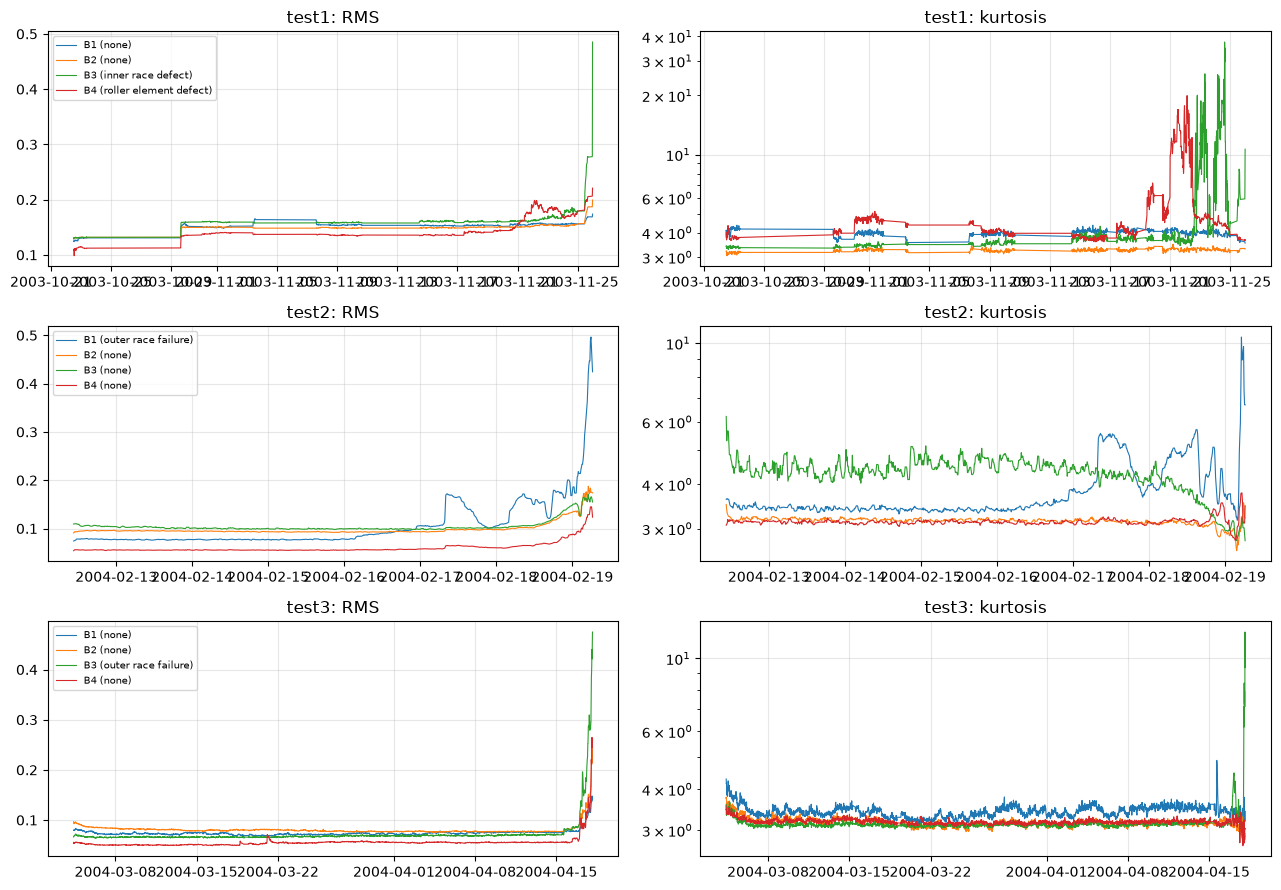

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex="row")
for i, (test, g) in enumerate(f.groupby("test_id")):
    for b, gb in g.groupby("bearing"):
        lab = f"B{b} ({gb.failure_mode.iloc[0]})"
        axes[i, 0].plot(gb.timestamp, gb.rms.rolling(6, min_periods=1).median(), lw=0.8, label=lab)
        axes[i, 1].plot(gb.timestamp, gb["kurtosis"].rolling(6, min_periods=1).median(), lw=0.8, label=lab)
    axes[i, 0].set_title(f"{test}: RMS"); axes[i, 1].set_title(f"{test}: kurtosis"); axes[i, 1].set_yscale("log")
    axes[i, 0].legend(fontsize=7)
plt.tight_layout()

Failed bearings show a sharp rise in RMS (energy) near end of life. In test 1, kurtosis (impulsiveness) rises much
earlier and much more than RMS. Both features are carried into the device telemetry.

In [5]:
f[["rms", "peak", "kurtosis", "crest_factor", "hf_energy_ratio"]].corr().round(2)

,rms,peak,kurtosis,crest_factor,hf_energy_ratio
rms,1.00,0.80,0.32,0.11,0.48
peak,0.80,1.00,0.71,0.64,0.45
kurtosis,0.32,0.71,1.00,0.68,0.33
crest_factor,0.11,0.64,0.68,1.00,0.16
hf_energy_ratio,0.48,0.45,0.33,0.16,1.00


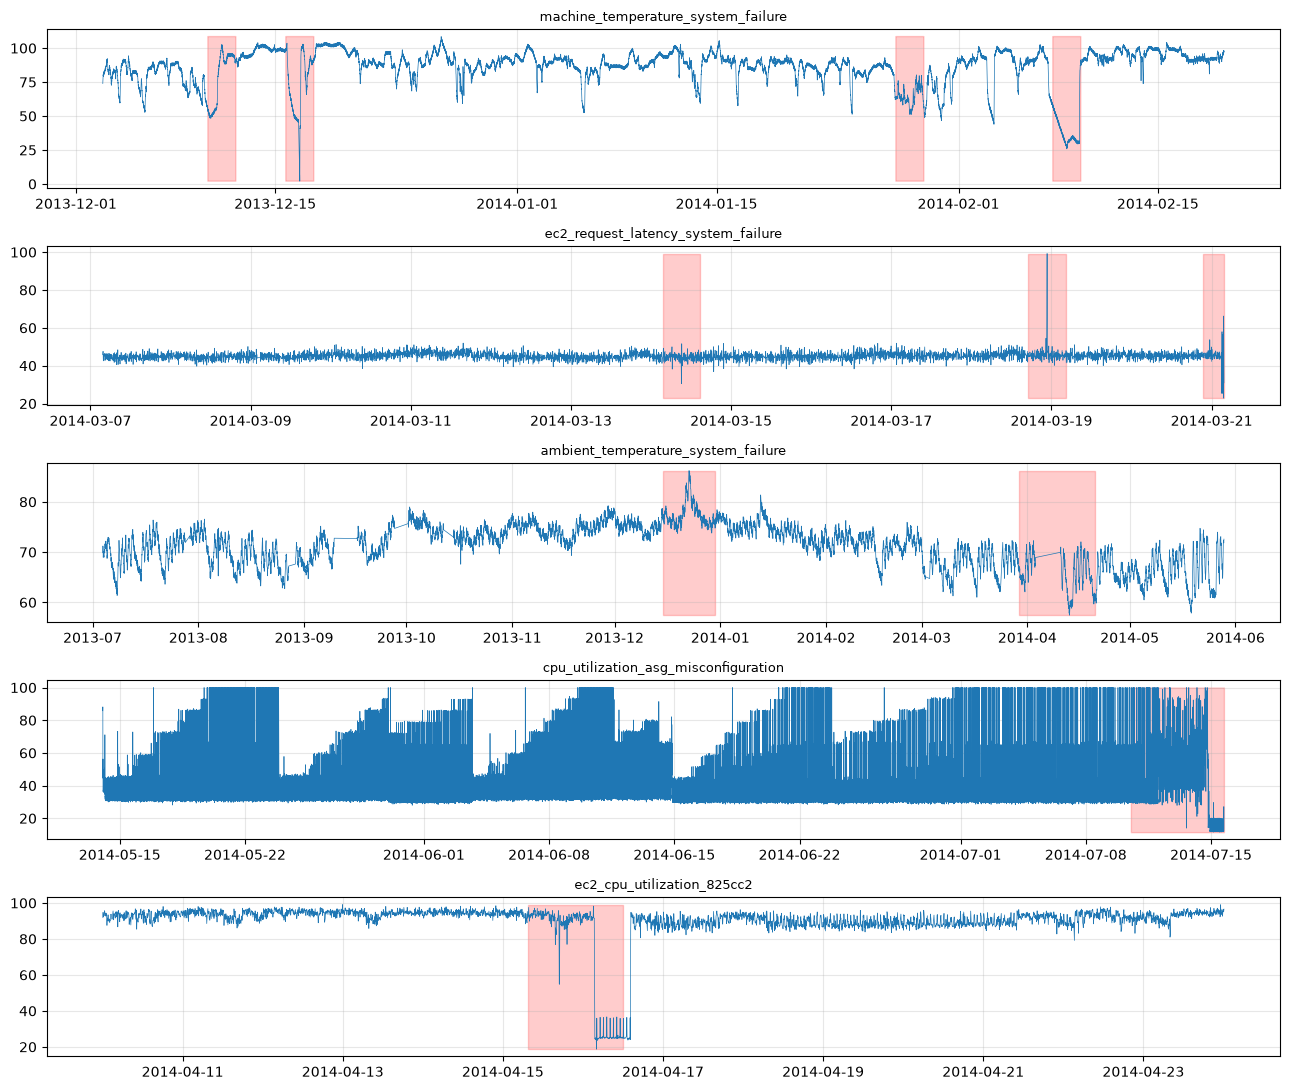

In [6]:
nab = load_all_nab()
fig, axes = plt.subplots(len(nab.series.unique()), 1, figsize=(13, 11))
for ax, (name, s) in zip(axes, nab.groupby("series", sort=False)):
    ax.plot(s.timestamp, s.value, lw=0.5)
    ax.fill_between(s.timestamp, s.value.min(), s.value.max(), where=s.in_anomaly_window, color="red", alpha=0.2)
    ax.set_title(name, fontsize=9)
plt.tight_layout()

Red bands are NAB's official anomaly windows. `ec2_request_latency_system_failure` (real request latency in ms) is
reused in notebook 02 as the response-time profile of each device.